# Podstawy AI – Zajęcia 1: zbiory rozmyte

**Jedna myśl na całe zajęcia:** ostra granica jest krucha – zmiękczamy ją do stopni. A potem każdy krok, który wydaje się „matematyczny”, okazuje się **decyzją projektową**.

Plan (90 min):
1. Funkcje przynależności – piszesz je sam (35 min)
2. Operacje na zbiorach rozmytych – co znaczy „i”, „lub”, „nie” (50 min)
3. Podsumowanie (5 min)

**Jak pracujemy:**
- **✏️** – piszesz kod. Definicje funkcji i operatorów są w prezentacji z wykładu.
- **🧪** – komórka testowa: po uruchomieniu pokaże ✅ albo ❌ z podpowiedzią, co jest nie tak.
- **❓** – odpowiadasz 2–3 zdaniami w komórce pod spodem.

Oddajesz ten notebook.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from functools import reduce


def sprawdz(nazwa, f, przypadki):
    """Testuje funkcję f: przypadki = lista (argumenty, oczekiwany_wynik)."""
    bledy = 0
    for args, oczekiwane in przypadki:
        try:
            wynik = f(*args)
            ok = wynik is not None and np.allclose(np.asarray(wynik, float), oczekiwane, atol=1e-6)
        except Exception as e:
            wynik, ok = f"BŁĄD: {e}", False
        if not ok:
            bledy += 1
            arg = ", ".join(str(np.round(a, 3).tolist()) if isinstance(a, np.ndarray) else str(a) for a in args)
            print(f"{nazwa}({arg}) = {wynik}, oczekiwano {oczekiwane}")
    print(f"{nazwa}: wszystkie testy OK" if bledy == 0 else f"   {nazwa}: {bledy} błędnych przypadków")

---
## Część 1. Funkcje przynależności

### 1.1 Ostra granica vs stopień przynależności

Klasycznie: „wysoka temperatura” to np. **powyżej 25 °C**. Albo tak, albo nie. Rozmyta wersja używa funkcji **γ** z wykładu. Oto jej implementacja – wzoruj się na niej w zadaniu 1.2.

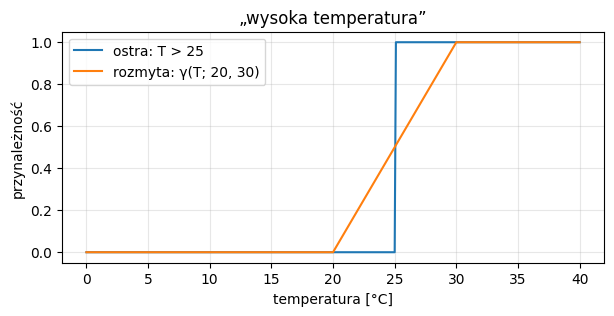

T = 24.9:  ostra = 0,  rozmyta = 0.49
T = 25.1:  ostra = 1,  rozmyta = 0.51


In [2]:
def gamma(x, a, b):
    """Funkcja γ: 0 dla x <= a, liniowo rośnie, 1 dla x >= b. Np. 'wysoki', 'duży'."""
    x = np.asarray(x, dtype=float)
    return np.clip((x - a) / (b - a), 0, 1)


x = np.linspace(0, 40, 401)
plt.figure(figsize=(7, 3))
plt.plot(x, (x > 25).astype(float), label="ostra: T > 25")
plt.plot(x, gamma(x, 20, 30), label="rozmyta: γ(T; 20, 30)")
plt.xlabel("temperatura [°C]"); plt.ylabel("przynależność"); plt.legend(); plt.grid(alpha=.3)
plt.title("„wysoka temperatura”"); plt.show()

for T in (24.9, 25.1):
    print(f"T = {T}:  ostra = {float(T > 25):.0f},  rozmyta = {float(gamma(T, 20, 30)):.2f}")

❓ **1a.** 24,9 °C i 25,1 °C różnią się o 0,2 stopnia. Co z tą różnicą robi definicja ostra, a co rozmyta? Która jest bliższa temu, jak mówią ludzie?

*Twoja odpowiedź:*

### 1.2 ✏️ Funkcje L i trójkątna

Zaimplementuj dwie funkcje z wykładu:
- **L(x; a, b)** – 1 dla x ≤ a, liniowo maleje, 0 dla x ≥ b (np. „niski”, „mały”),
- **t(x; a, b, c)** – trójkąt: 0 dla x ≤ a, rośnie do 1 w punkcie b, maleje do 0 w c (np. „średni”).

Funkcje muszą działać zarówno dla pojedynczej liczby, jak i dla całej tablicy `np.array`. Podpowiedź: zobacz, jak zbudowana jest `gamma`. Przydadzą się `np.clip` i `np.minimum`.

In [ ]:
def L(x, a, b):
    x = np.asarray(x, dtype=float)
    #  TODO
    return np.zeros_like(x)


def t(x, a, b, c):
    x = np.asarray(x, dtype=float)
    #  TODO
    return np.zeros_like(x)

In [ ]:
# 🧪 Testy – uruchom bez zmian
sprawdz("L", L, [((0, 10, 20), 1), ((10, 10, 20), 1), ((15, 10, 20), 0.5), ((20, 10, 20), 0), ((30, 10, 20), 0),
                 ((np.array([5, 12.5, 25]), 10, 20), [1, 0.75, 0])])
sprawdz("t", t, [((0, 10, 20, 40), 0), ((15, 10, 20, 40), 0.5), ((20, 10, 20, 40), 1), ((30, 10, 20, 40), 0.5),
                 ((40, 10, 20, 40), 0), ((50, 10, 20, 40), 0), ((np.array([10, 20, 35]), 10, 20, 40), [0, 1, 0.25])])

xx = np.linspace(0, 50, 501)
plt.figure(figsize=(7, 3))
plt.plot(xx, L(xx, 10, 20), label="L(x; 10, 20)")
plt.plot(xx, t(xx, 10, 20, 40), label="t(x; 10, 20, 40)")
plt.plot(xx, gamma(xx, 30, 45), label="γ(x; 30, 45)")
plt.legend(); plt.grid(alpha=.3); plt.show()

### 1.3 ✏️ Prędkość samochodu

Zdefiniuj cztery zbiory na przedziale 0–200 km/h: **mała**, **średnia**, **duża**, **bardzo duża**. Użyj swoich `L`, `t` i `gamma`. Poniższe liczby są celowo złe – popraw je.

In [ ]:
v = np.linspace(0, 200, 401)

#  TODO: popraw parametry
mala        = L(v, 10, 20)
srednia     = t(v, 20, 30, 40)
duza        = t(v, 40, 50, 60)
bardzo_duza = gamma(v, 60, 70)

plt.figure(figsize=(8, 3))
for y, n in [(mala, "mała"), (srednia, "średnia"), (duza, "duża"), (bardzo_duza, "bardzo duża")]:
    plt.plot(v, y, label=n)
plt.xlabel("prędkość [km/h]"); plt.legend(); plt.grid(alpha=.3); plt.show()

❓ **1b.** Dlaczego wybrałeś takie liczby? Czy „duża prędkość” w mieście i na autostradzie to ten sam zbiór?

❓ **1c.** Porównaj swój wykres z osobą obok. Jeśli się różnią – kto ma rację?

*Twoja odpowiedź:*

### 1.4 ✏️ „Bardzo” i „trochę” (koncentracja i rozcieńczenie)

Zaimplementuj dwie operacje z wykładu: **CON** („bardzo”) i **DIL** („trochę”). Każda to jedna linijka.

In [ ]:
def CON(A):
    #  TODO
    return A


def DIL(A):
    #  TODO
    return A

In [ ]:
# 🧪 Testy
sprawdz("CON", CON, [((0.5,), 0.25), ((1.0,), 1.0), ((np.array([0, 0.3, 0.9]),), [0, 0.09, 0.81])])
sprawdz("DIL", DIL, [((0.25,), 0.5), ((1.0,), 1.0), ((np.array([0, 0.49, 0.81]),), [0, 0.7, 0.9])])

# Wykres kontrolny – porównaj z prezentacją
xx = np.linspace(0, 50, 501)
A_ = t(xx, 10, 20, 40)
plt.figure(figsize=(7, 2.6))
plt.plot(xx, A_, label="A = t(x; 10, 20, 40)")
plt.plot(xx, CON(A_), "--", label="CON(A)")
plt.plot(xx, DIL(A_), ":", label="DIL(A)")
plt.title("Wykres kontrolny"); plt.legend(fontsize=8); plt.grid(alpha=.3); plt.show()

plt.figure(figsize=(8, 3))
plt.plot(v, duza, label="duża (Twoja)")
plt.plot(v, CON(duza), "--", label="CON(duża) = „bardzo duża” wg wzoru")
plt.plot(v, DIL(duza), ":", label="DIL(duża) = „trochę duża”")
plt.plot(v, bardzo_duza, label="bardzo duża (Twoja z 1.3)")
plt.xlabel("prędkość [km/h]"); plt.legend(fontsize=8); plt.grid(alpha=.3); plt.show()

❓ **1d.** Porównaj CON(duża) z Twoim zbiorem „bardzo duża”. Czym się różnią kształtem i położeniem? Które lepiej oddaje, co ludzie mają na myśli, mówiąc „bardzo szybko”?

*Twoja odpowiedź:*

---
## Część 2. Operacje na zbiorach rozmytych

W logice klasycznej „i” to część wspólna, „lub” to suma, „nie” to dopełnienie – i są **jednoznaczne**. W logice rozmytej „i” to dowolna **t-norma**, „lub” to **s-norma**, i jest ich wiele.

### 2.1 ✏️ Implementacja operatorów

Zaimplementuj operatory z wykładu. Wszystkie działają element po elemencie na tablicach (`np.minimum`, `np.maximum`, `np.where` …).

| | „i” (t-norma) | „lub” (s-norma) |
|---|---|---|
| Zadeha | minimum | maksimum |
| algebraiczne | iloczyn | suma probabilistyczna |
| Łukasiewicza | iloczyn ograniczony | suma ograniczona |
| drastyczne | iloczyn drastyczny | suma drastyczna |

oraz negację (dopełnienie).

In [ ]:
def NIE(a):
    #  TODO
    return a

# t-normy ("i")
def T_min(a, b):
    #  TODO
    return a

def T_iloczyn(a, b):
    #  TODO
    return a

def T_luk(a, b):          # iloczyn ograniczony (Łukasiewicza)
    #  TODO
    return a

def T_drast(a, b):        # iloczyn drastyczny
    #  TODO
    return a

# s-normy ("lub")
def S_max(a, b):
    #  TODO
    return a

def S_prob(a, b):         # suma probabilistyczna
    #  TODO
    return a

def S_luk(a, b):          # suma ograniczona (Łukasiewicza)
    #  TODO
    return a

def S_drast(a, b):        # suma drastyczna
    #  TODO
    return a

In [ ]:
# Testy
a, b = np.array([0.0, 0.3, 0.6, 1.0, 0.8]), np.array([0.5, 0.9, 0.6, 0.4, 0.0])
sprawdz("NIE",       NIE,       [((a,), [1, 0.7, 0.4, 0, 0.2])])
sprawdz("T_min",     T_min,     [((a, b), [0, 0.3, 0.6, 0.4, 0])])
sprawdz("T_iloczyn", T_iloczyn, [((a, b), [0, 0.27, 0.36, 0.4, 0])])
sprawdz("T_luk",     T_luk,     [((a, b), [0, 0.2, 0.2, 0.4, 0])])
sprawdz("T_drast",   T_drast,   [((a, b), [0, 0, 0, 0.4, 0])])
sprawdz("S_max",     S_max,     [((a, b), [0.5, 0.9, 0.6, 1, 0.8])])
sprawdz("S_prob",    S_prob,    [((a, b), [0.5, 0.93, 0.84, 1, 0.8])])
sprawdz("S_luk",     S_luk,     [((a, b), [0.5, 1, 1, 1, 0.8])])
sprawdz("S_drast",   S_drast,   [((a, b), [0.5, 1, 1, 1, 0.8])])

# Pary (t-norma, s-norma) – przydadzą się dalej
PARY = {
    "Zadeh (min/max)":        (T_min, S_max),
    "algebraiczne":           (T_iloczyn, S_prob),
    "Łukasiewicz":            (T_luk, S_luk),
    "drastyczne":             (T_drast, S_drast),
}

In [ ]:
# Wykres kontrolny – porównaj z prezentacją
a_ = np.linspace(0, 1, 201)
b_ = 0.6
fig, osie = plt.subplots(1, 2, figsize=(11, 3), sharey=True)
for nazwa, (T, S) in PARY.items():
    osie[0].plot(a_, T(a_, b_), lw=2, label=nazwa)
    osie[1].plot(a_, S(a_, b_), lw=2, label=nazwa)
osie[0].set_title("„i”:  T(a, 0.6)"); osie[1].set_title("„lub”:  S(a, 0.6)")
for o in osie:
    o.set_xlabel("a"); o.grid(alpha=.3)
osie[0].legend(fontsize=8); plt.tight_layout(); plt.show()

### 2.2 Jak wyglądają różne „i”?

Weźmy dwa zbiory: **A = „średnia temperatura”** i **B = „wysoka temperatura”**. Ile prawdy jest w zdaniu „temperatura jest średnia **i** wysoka” – dla każdego operatora?

In [ ]:
x = np.linspace(0, 40, 401)
A_t = t(x, 10, 20, 30)
B_t = gamma(x, 20, 30)

fig, osie = plt.subplots(1, 4, figsize=(16, 3), sharey=True)
for os_, (nazwa, (T, S)) in zip(osie, PARY.items()):
    os_.plot(x, A_t, ":", c="gray"); os_.plot(x, B_t, ":", c="gray")
    os_.fill_between(x, T(A_t, B_t), alpha=.5, label="A i B")
    os_.plot(x, S(A_t, B_t), "k", lw=1, label="A lub B")
    os_.set_title(f"{nazwa}\nmax(A i B) = {np.max(T(A_t, B_t)):.2f}")
    os_.set_xlabel("°C"); os_.grid(alpha=.3)
osie[0].legend(fontsize=8); plt.tight_layout(); plt.show()

# Dwóch niezależnych świadków: każdy jest pewny na 70%, że to był on. „Świadek 1 LUB świadek 2”:
for nazwa, (T, S) in PARY.items():
    print(f"{nazwa:<18} S(0.7, 0.7) = {float(S(0.7, 0.7)):.2f}")

❓ **2a.** Uszereguj cztery „i” od dającego największe wartości do najmniejszych. Przy którym operatorze zdanie „temperatura jest średnia i wysoka” **nigdy** nie jest choć trochę prawdziwe? Czy to rozsądne?

❓ **2b.** Dwóch świadków, każdy pewny na 70%. Ile wynosi „świadek 1 LUB świadek 2” dla każdej pary? Który wynik jest poprawny?

*Twoja odpowiedź:*

### 2.3 ✏️ Które prawa logiki przetrwały?

W logice klasycznej (prawda = 1, fałsz = 0) zachodzi pięć praw:

| prawo | zapis | po ludzku |
|---|---|---|
| przemienność | A ∪ B = B ∪ A | kolejność w „lub” nie ma znaczenia |
| idempotentność | A ∩ A = A | „A i A” to po prostu A |
| niesprzeczność | A ∩ ¬A = ∅ | „A i nie-A” jest zawsze fałszem |
| wyłączony środek | A ∪ ¬A = X | „A lub nie-A” jest zawsze prawdą – trzeciej możliwości nie ma |
| de Morgan | ¬(A ∪ B) = ¬A ∩ ¬B | „nie (A lub B)” to „nie A i nie B” |

Czy przetrwają, gdy prawda ma stopnie? Zamiast dowodzić na papierze – sprawdzamy na siatce wszystkich wartości od 0 do 1. Uzupełnij dwa brakujące prawa. Pozostałe są przykładem, jak to zapisać.

In [ ]:
siatka = np.linspace(0, 1, 21)
a, b = np.meshgrid(siatka, siatka)       # wszystkie pary (a, b) z siatki

def prawa(T, S):
    return {
        "przemienność A∪B = B∪A":    np.allclose(S(a, b), S(b, a)),
        "idempotentność A∩A = A":    np.allclose(T(a, a), a),
        "niesprzeczność A∩¬A = ∅":   np.allclose(T(a, NIE(a)), 0),
        #  TODO: wyłączony środek A∪¬A = X  (X to zbiór, w którym wszystko ma przynależność 1)
        "wyłączony środek A∪¬A = X": False,
        #  TODO: prawo de Morgana ¬(A∪B) = ¬A ∩ ¬B
        "de Morgan ¬(A∪B) = ¬A∩¬B":  False,
    }

wyniki = {nazwa: prawa(T, S) for nazwa, (T, S) in PARY.items()}
print(f"{'prawo':<28}" + "".join(f"{n.split()[0]:>14}" for n in PARY))
for prawo in next(iter(wyniki.values())):
    print(f"{prawo:<28}" + "".join(f"{'✓' if wyniki[n][prawo] else '✗':>14}" for n in PARY))

In [ ]:
# Jak wygląda „A i nie-A” dla wysokiej temperatury?
A_w = gamma(x, 20, 30)
plt.figure(figsize=(7, 3))
plt.plot(x, A_w, label="A = wysoka temp.")
plt.plot(x, NIE(A_w), label="nie-A")
for nazwa, (T, S) in PARY.items():
    plt.plot(x, T(A_w, NIE(A_w)), lw=2, label=f"A i nie-A: {nazwa}")
plt.xlabel("temperatura [°C]"); plt.legend(fontsize=7); plt.grid(alpha=.3); plt.show()

❓ **2c.** Które prawa logiki klasycznej przetrwały dla każdej pary, a które nie? Czy któraś para zachowuje **wszystkie**?

❓ **2d.** Dla pary Zadeha „A i nie-A” osiąga 0,5 przy 25 °C. To błąd czy zaleta? (Czy o 25 °C da się uczciwie powiedzieć, że jest „trochę gorąco i trochę nie”?)

*Twoja odpowiedź:*

### 2.4 Wybór uczelni – czy operator zmienia decyzję?

Kandydat dostał się na 4 wydziały. Chce, żeby wydział był **wysoko w rankingu I blisko domu I miał dobrą wymianę I dawał dobre szanse na pracę**. Najpierw zamieniamy liczby na stopnie spełnienia kryteriów – Twoimi funkcjami `L` i `gamma`.

In [ ]:
wydzialy = {
    #          miejsce w rankingu, odległość [km], uczelnie partnerskie, zatrudnienie [%]
    "w1": (19, 72, 20, 78),
    "w2": (4,  92, 35, 92),
    "w3": (35, 10, 12, 70),
    "w4": (12, 50,  7, 85),
}

def kryteria(ranking, odleglosc, wymiana, praca):
    return [
        L(ranking, 5, 40),        # 'wysoko w rankingu'
        L(odleglosc, 20, 150),    # 'blisko domu'
        gamma(wymiana, 5, 30),    # 'dobra wymiana'
        gamma(praca, 60, 90),     # 'dobre szanse na pracę'
    ]

stopnie = {w: kryteria(*d) for w, d in wydzialy.items()}
print("        ranking  blisko  wymiana  praca")
for w, s in stopnie.items():
    print(w, "  ", "   ".join(f"{float(x):5.2f}" for x in s))

Teraz łączymy cztery kryteria Twoimi t-normami. `reduce(T, [k1, k2, k3, k4])` liczy T(T(T(k1, k2), k3), k4) – czyli „k1 i k2 i k3 i k4”. Dla porównania dodajemy średnią, która **nie** jest t-normą.

In [ ]:
operatory = {nazwa: (lambda T: (lambda s: float(reduce(T, s))))(T) for nazwa, (T, S) in PARY.items()}
operatory["średnia (to NIE „i”)"] = lambda s: float(np.mean(s))

print(f"{'operator':<22}" + "".join(f"{w:>7}" for w in wydzialy) + "   ranking")
for nazwa, op in operatory.items():
    oceny = {w: op(s) for w, s in stopnie.items()}
    kolejnosc = " > ".join(sorted(oceny, key=oceny.get, reverse=True))
    print(f"{nazwa:<22}" + "".join(f"{o:7.2f}" for o in oceny.values()) + "   " + kolejnosc)

❓ **2e.** Który wydział wygrywa przy minimum, a który przy iloczynie? Spójrz na tabelę stopni i wyjaśnij, **dlaczego** zwycięzca się zmienia.

❓ **2f.** Opisz minimum, iloczyn i Łukasiewicza jednym zdaniem „po ludzku” (np. minimum = „łańcuch jest tak mocny, jak jego najsłabsze ogniwo”). Który z nich najlepiej oddaje to, jak **Ty** wybierałbyś uczelnię?

❓ **2g.** Średnia stawia w4 na drugim miejscu, choć wymiana ma tam ocenę 0,08. Dlaczego średnia to nie jest „i”? Kiedy mimo to byłaby rozsądnym wyborem?

*Twoja odpowiedź:*

---
## Część 3. Podsumowanie

❓ **3a.** Wymień trzy miejsca z dzisiejszych zajęć, w których podjąłeś decyzję, którą ktoś inny mógłby rozsądnie podjąć inaczej.

❓ **3b.** Wszystkie liczby w tym notebooku (parametry funkcji, wybór operatora) wpisał człowiek. Jak inaczej można by je uzyskać, gdybyśmy mieli dane?

*Twoja odpowiedź:*